<div style="text-align:center; line-height:1.0;">
    <span style="font-size:32px; font-weight:bold;">Computational Techniques for Meteorology Lab</span><br>
    <span style="font-size:24px;">MET 3602 (ENS 4901 Section 2)</span><br>
    <span style="font-size:20px;">Dr. Steven Lazarus</span><br>
    <span style="font-size:20px;">Link 332</span><br>
    <span style="font-size:20px;">Dr. L Office Hours: T/Th 10:00-11:30 a.m.</span><br>
    <span style="font-size:20px;">Trey Rockey Office Hours: M 12:30-2:30 p.m. & T 10:00 a.m.-12:00 p.m.</span><br>
</div>

## Instructions

- Answer all questions and place answers in the code cells provided, and ensure all outputs are displayed. 
- Save (**rename**) the notebook as `Lab_Assignment_07_lastname.ipynb` and submit to Canvas by 11:59 p.m. Sunday, October 18.

### Learning Objectives

By the end of this lab, you will be able to: 

- Open and explore NOAA climate datasets with xarray.
- Examine climate data variables, dimensions, and metadata.
- Identify valid data and temperature extremes.
- Work with datetime information in xarray.
- Create climate maps using Cartopy and Matplotlib.
- Build multi-panel visualizations of meteorological fields.

### Week 9 Lab: Daily Climate Data Analysis <span style="color:red">  50 pts</span>

This lab guides you through analyzing daily climate data from NOAA's NClimGrid dataset using Python and `xarray`. You will explore temperature and precipitation variables, identify extremes, and visualize spatial patterns.

See:
https://www.ncei.noaa.gov/products/land-based-station/nclimgrid-daily

**Notes:**  

Make sure documentation (e.g., comment block and comments throughout code) is present in your source code

In [ ]:
from datetime import datetime
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

## Section 1: Open & Explore the NClimGrid Data <span style="color:red">25 pts</span>

### Question 1: Open the Dataset <span style="color:red">2 pts</span>

**a.)** Use `xarray` to open the October 2026 NOAA NClimGrid dataset from the Amazon (AWS S3 Explorer) data bucket.

https://noaa-nclimgrid-daily-pds.s3.amazonaws.com/index.html#access/grids/

**b.)** Pop the data (i.e., dump it to the screen!)

In [ ]:
# a.) Open Data Set from Amazon Bucket
import s3fs
import xarray as xr

fs = s3fs.S3FileSystem(anon=True)

# Note that the 'prelim' in the filename means that the data are not fully populated for the month

fs.get(
    "noaa-nclimgrid-daily-pds/access/grids/2026/ncdd-202610-grd-prelim.nc",
    "ncdd-202610-grd-prelim.nc"
)

ds = xr.open_dataset("ncdd-202610-grd-prelim.nc")

In [ ]:
#b.) Pop


### Question 2: Variables  <span style="color:red">  2 pts</span>
Use the `keys` method to:

**a.)** List the variables  

**b.)** Print the # of variables 

In [ ]:
#a.)


In [ ]:
#b.)


### Question 3: Units!!! <span style="color:red">  4 pts</span>

**a.)** List (print) the units for each variable  

### Question 4: Query the data <span style="color:red">3 pts</span>
Apply the 'key' method to the maximum temperature to:

**a.)** pull the # of dimensions  
**b.)** pull the shape  
**c.)** Which dimension will change depending on the dataset?

In [ ]:
#a.) 


In [ ]:
#b.) 


In [ ]:
#c.)


### Question 5: The Amazon bucket 'lags' by a few days! <span style="color:red">4 pts</span> 

Because this is an nClimGrid-Daily grid, the most recent month is incomplete, so the grids are filled with the missing-data special value -999.9921875.

**a.)** Determine the time of the most recent available data. Hint: You can check 'future' data (use `.isel(time=-1)`) and look at the max and min values. If the grid max and min are -999 for a given time then you know the grid has not yet been populated!

You can do this manually (not a great idea), or you can apply a Boolean operation that looks for values < -100 throughout the time grids ('True')...

In [ ]:
#a.)


### Question 6: Identify Temperature Extremes <span style="color:red">10 pts</span>

**a.** Use the xarray datetime object returned in question 5 to define the day index associated with the most recent data.  

**b.** Use the `.isel` method to select the most recent data and extract (use the key method) the maximum and minimum temperatures **for that day only**. Make sure you assign variable names to each, and print only the scalar values.

**c.** Use the `.where` method to determine the locations of the maximum of maximum temperatures (`tmax`) and the minimum of minimum temperatures (`tmin`). Use an f-string to print these 4 values. 

**d.** Use the `.nanargmax` method to print the
- x and y indices of the maximum in the 2D `tmax` array
- use these indices to extract and print: 1) the maximum value and 2) the associated latitude/longitude

**e.)** Repeat d) for the minimum temperature as well!

In [ ]:
#a.)


In [ ]:
#b.) 
#Assign variable names for max of maxes and mins of mins temps for specified day


In [ ]:
#c.)


In [ ]:
#d.)
# Max


#e.)
# Min



## Section 2: Plotting <span style="color:red">25 pts</span>

### Question 1: Datetime String <span style="color:red">7 pts</span>
**a.)** Extract the time and date(use the key method). Hint: You can use the combined datetime/xarray methods `.dt.year[0].item()`. Define the following elements (in this precise order!):
- year  
- month  
- day  
- hour  
- minute  
- second

**b.)** Use an f-string to print the date as `Valid:` `YYYY-MM-DDTHH:MM:SS`

In [ ]:
#a.)
#Separate the time and date


#b.)



### Question 2: Plotting (1-panel)  <span style="color:red">10 pts</span>
Create a filled contour plot (not a raster) of the maximum temperature for the selected day with the following attributes (do NOT hard-code any of this!):

At the top add a 
- left-justified title "Maximum Temperature (°C)" 
- right-justified datetime string "Valid: YYYY-MM-DD HH:MM:SS"  (see Question 1b above)

For the plot
- use a contour fill range that maximizes the fidelity  
  (I used 0°C-to-40°C range with a 2°C interval)  
- apply a 'jet' colormap  
- include a color bar
- include coastlines
- inlcude borders
- include states
- add the maximum temperature (black text, i.e. 'MaxT = { }°C') and the location (filled white circle). 

In [ ]:
# Plot
plt.figure(1, figsize=(15, 13))
ax = plt.subplot(111, projection=ccrs.LambertConformal(central_longitude=-100, standard_parallels=(25, 40)))
ax.set_extent([-125, -65, 25, 50], ccrs.PlateCarree())


# Add maximum point marker and text


#Add states and borders


# Add the date time and title


### Question 3: Plotting (4-panel) <span style="color:red">8 pts</span>
Create a 2 x 2 graphic (use a for loop!). The graphic should include 
- maximum and minimum temperature on the first row
- average temperature and precipitation on the second row
- a title for each subplot, e.g.,

```Python
titles    = ['Maximum Temperature (°C)',
             'Minimum Temperature (°C)',
             'Average Temperature (°C)',
             'Precipitation (mm)']
```
- individual color bars below each figure
     Use the jet colormap for the temperatures and blues for precipitation, e.g.,

Set up dictionaries for each variable
```Python
cmaps = {
    'tmax': 'jet',
    'tmin': 'jet',
    'tavg': 'jet',
    'prcp': 'Blues'
}


levels = {
    'tmax': np.arange(0, 40, 2),
    'tmin': np.arange(-10, 30, 2),  # <-- your distinct Tmin scale
    'tavg': np.arange(0, 40, 2),
    'prcp': np.arange(0, 101, 5)
}
```

- a centered title "NOAA nVlimGrid Daily" at the top, and "Valid: YYYY-MM-DD HH:MM:SS" centered just below it

In [ ]:
#Plot here!
fig = plt.figure(figsize=(16,12))



# Set up dictionary for each variable



#For loop here





#Coastline, borders and states
 


#ClimGrid Daily Title



#Plot additions
plt.tight_layout()
plt.show()

DRL's Figure 👀

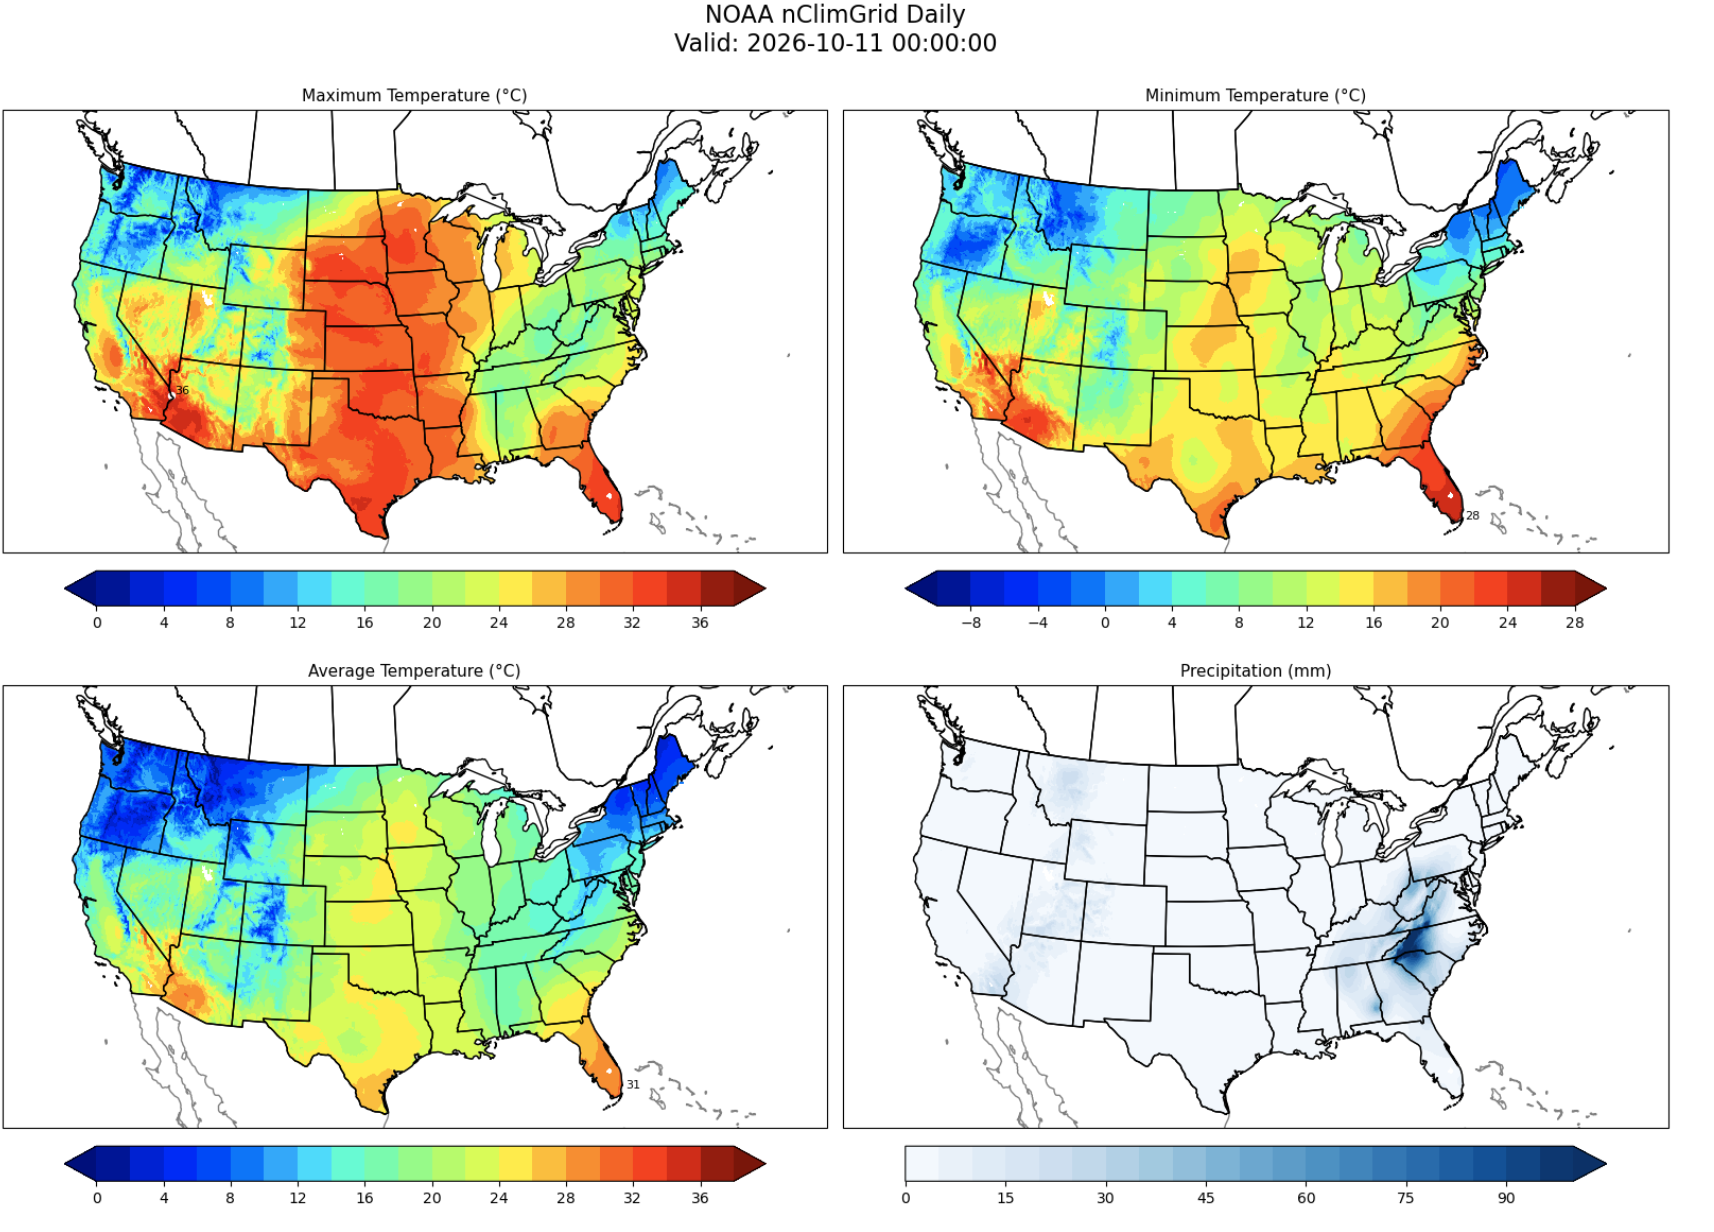